# AME 5052: Applied Machine Learning Lab
## Practical Record — Questions 1, 2 and 3

**Tools:** Python, NumPy, pandas, Matplotlib, scikit-learn, SciPy  
**Purpose:** Implement the algorithms specified in the assignment, inspect their outputs, and evaluate their performance using appropriate metrics.

### Notes
- Run the notebook from top to bottom.
- The examples use built-in datasets or reproducible synthetic data, so no external dataset download is required.
- Exact numerical results may vary slightly with library versions. The code prints the results generated in your environment.
- For classification, higher accuracy/F1 and lower log loss are generally preferred. For regression, lower MAE/MSE/RMSE and higher \(R^2\) are generally preferred. Clustering metrics require care: silhouette is higher when clusters are more separated, while ARI uses known labels only for an external evaluation in this demonstration.

## Experiment 0 — Import libraries and set up evaluation helpers

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes, load_breast_cancer, load_iris, make_blobs
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, log_loss,
    silhouette_score, adjusted_rand_score
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

def regression_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mean_squared_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

def classification_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0)
    }

print("Libraries imported successfully.")

Libraries imported successfully.


# Question 1 — Supervised Learning

## 1(a). Linear Regression, Ridge Regression and Lasso Regression

**Objective:** Fit linear models to predict a continuous target and compare ordinary least squares with L2 (Ridge) and L1 (Lasso) regularization.

**Theory:** Linear regression estimates coefficients by minimizing squared prediction errors. Ridge adds a penalty proportional to the sum of squared coefficients; Lasso adds a penalty proportional to the sum of absolute coefficients. Regularization can reduce overfitting. Features are standardized for Ridge and Lasso because the penalty is scale-sensitive.

,MAE,MSE,RMSE,R2
Model,,,,
Linear Regression,42.794,2900.194,53.853,0.453
Ridge (alpha=1.0),42.812,2892.015,53.777,0.454
Lasso (alpha=0.1),42.805,2884.624,53.709,0.456


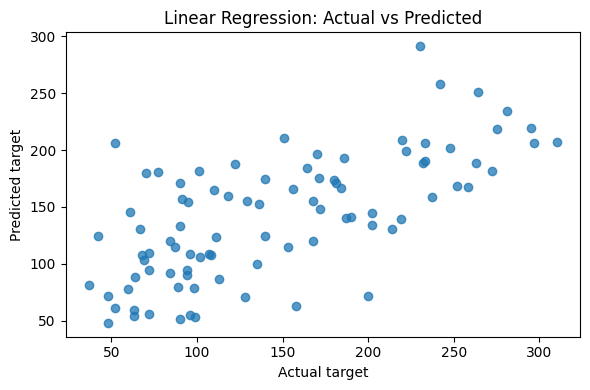

In [2]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso

diabetes = load_diabetes(as_frame=True)
X_reg = diabetes.data
y_reg = diabetes.target

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=RANDOM_STATE
)

reg_models = {
    "Linear Regression": LinearRegression(),
    "Ridge (alpha=1.0)": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Lasso (alpha=0.1)": make_pipeline(StandardScaler(), Lasso(alpha=0.1, max_iter=10000))
}

reg_results = []
reg_predictions = {}
for name, model in reg_models.items():
    model.fit(Xr_train, yr_train)
    pred = model.predict(Xr_test)
    reg_predictions[name] = pred
    reg_results.append({"Model": name, **regression_metrics(yr_test, pred)})

regression_table = pd.DataFrame(reg_results).set_index("Model").round(3)
display(regression_table)

# Visualize actual vs predicted values for the linear model
plt.figure(figsize=(6, 4))
plt.scatter(yr_test, reg_predictions["Linear Regression"], alpha=0.75)
plt.xlabel("Actual target")
plt.ylabel("Predicted target")
plt.title("Linear Regression: Actual vs Predicted")
plt.tight_layout()
plt.show()

**Result / inference:** The table reports MAE, MSE, RMSE and \(R^2\) for all three models. Lower error values indicate better predictions on the held-out test data. Ridge and Lasso shrink coefficients; Lasso can set some coefficients exactly to zero. The best model should be selected from test/validation performance rather than assumed in advance.

## 1(b). Decision Tree Classification — Entropy, Information Gain and Gini Impurity

**Objective:** Train decision trees using Gini impurity and entropy, and compare their classification performance.

**Theory:** Gini impurity measures how often a randomly selected sample would be incorrectly labelled if assigned a class according to the node's class distribution. Entropy measures uncertainty. Information gain is the reduction in entropy after a split:

\[
IG = H(parent) - \sum_j \frac{n_j}{n} H(child_j)
\]

Scikit-learn's `criterion="entropy"` selects splits using information gain (equivalently, entropy reduction); `criterion="gini"` uses Gini impurity.


 Decision Tree — Gini
[[49  4]
 [ 4 86]]
              precision    recall  f1-score   support

   malignant       0.92      0.92      0.92        53
      benign       0.96      0.96      0.96        90

    accuracy                           0.94       143
   macro avg       0.94      0.94      0.94       143
weighted avg       0.94      0.94      0.94       143


 Decision Tree — Entropy / Information Gain
[[49  4]
 [ 3 87]]
              precision    recall  f1-score   support

   malignant       0.94      0.92      0.93        53
      benign       0.96      0.97      0.96        90

    accuracy                           0.95       143
   macro avg       0.95      0.95      0.95       143
weighted avg       0.95      0.95      0.95       143



,Accuracy,Precision,Recall,F1
Model,,,,
Decision Tree — Gini,0.944,0.956,0.956,0.956
Decision Tree — Entropy / Information Gain,0.951,0.956,0.967,0.961


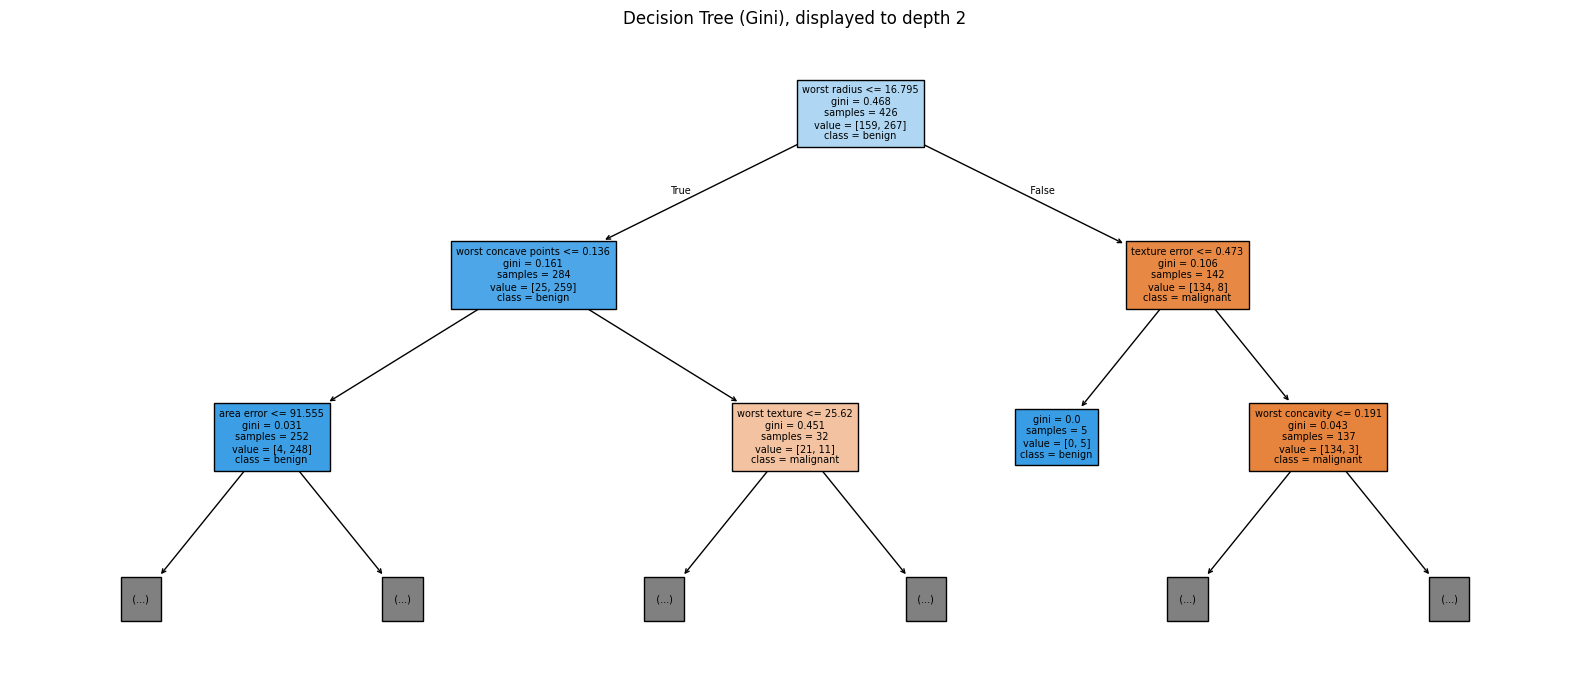

In [3]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

cancer = load_breast_cancer(as_frame=True)
X_cls = cancer.data
y_cls = cancer.target

X_train, X_test, y_train, y_test = train_test_split(
    X_cls, y_cls, test_size=0.25, stratify=y_cls, random_state=RANDOM_STATE
)

tree_models = {
    "Decision Tree — Gini": DecisionTreeClassifier(criterion="gini", max_depth=4, random_state=RANDOM_STATE),
    "Decision Tree — Entropy / Information Gain": DecisionTreeClassifier(criterion="entropy", max_depth=4, random_state=RANDOM_STATE)
}

tree_results = []
for name, model in tree_models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    tree_results.append({"Model": name, **classification_metrics(y_test, pred)})
    print("\n", name)
    print(confusion_matrix(y_test, pred))
    print(classification_report(y_test, pred, target_names=cancer.target_names, zero_division=0))

display(pd.DataFrame(tree_results).set_index("Model").round(3))

plt.figure(figsize=(16, 7))
plot_tree(tree_models["Decision Tree — Gini"], feature_names=X_cls.columns,
          class_names=cancer.target_names, filled=True, max_depth=2, fontsize=7)
plt.title("Decision Tree (Gini), displayed to depth 2")
plt.tight_layout()
plt.show()

**Result / inference:** Compare the accuracy, precision, recall and F1-score. The confusion matrix shows correct and incorrect predictions by class. A deeper tree can fit training data closely but may overfit; controlling `max_depth` is one way to limit complexity.

## 1(c). Logistic Regression — Sigmoid, Decision Boundary, L1 and L2 Regularization

**Objective:** Use logistic regression for binary classification and compare L2 and L1 penalties.

**Theory:** Logistic regression converts a linear score \(z = w^T x + b\) into a probability using the sigmoid function:

\[
\sigma(z)=\frac{1}{1+e^{-z}}
\]

With the default probability threshold of 0.5, the decision boundary is where \(w^T x+b=0\). L2 regularization (`penalty="l2"`) discourages large coefficients; L1 regularization (`penalty="l1"`) can produce sparse coefficients. Features are standardized.

,Accuracy,Precision,Recall,F1,Log loss
Model,,,,,
Logistic Regression — L2 (Ridge-style),0.986,0.9889,0.9889,0.9889,0.0679
Logistic Regression — L1 (Lasso-style),0.993,0.9890,1.0000,0.9945,0.0674


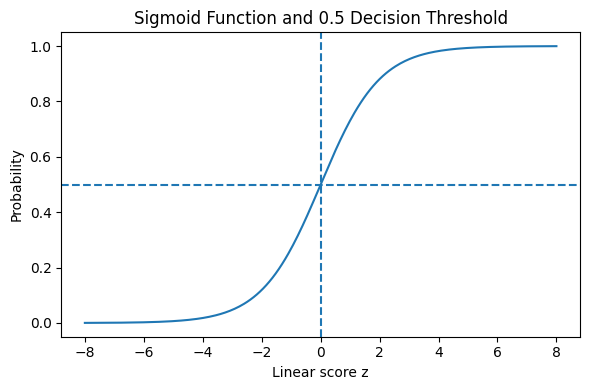

In [4]:
from sklearn.linear_model import LogisticRegression

log_models = {
    "Logistic Regression — L2 (Ridge-style)": make_pipeline(
        StandardScaler(), LogisticRegression(penalty="l2", C=1.0, max_iter=5000, random_state=RANDOM_STATE)
    ),
    "Logistic Regression — L1 (Lasso-style)": make_pipeline(
        StandardScaler(), LogisticRegression(penalty="l1", solver="liblinear", C=1.0, max_iter=5000, random_state=RANDOM_STATE)
    )
}

log_results = []
for name, model in log_models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    probs = model.predict_proba(X_test)
    row = {"Model": name, **classification_metrics(y_test, pred), "Log loss": log_loss(y_test, probs)}
    log_results.append(row)

display(pd.DataFrame(log_results).set_index("Model").round(4))

# Demonstrate sigmoid and the 0.5 probability threshold
z = np.linspace(-8, 8, 300)
sigmoid = 1 / (1 + np.exp(-z))
plt.figure(figsize=(6, 4))
plt.plot(z, sigmoid)
plt.axhline(0.5, linestyle="--")
plt.axvline(0, linestyle="--")
plt.xlabel("Linear score z")
plt.ylabel("Probability")
plt.title("Sigmoid Function and 0.5 Decision Threshold")
plt.tight_layout()
plt.show()

**Result / inference:** Compare classification metrics and log loss. Log loss evaluates the quality of predicted probabilities, not just class labels. In scikit-learn, `C` is inverse regularization strength: smaller `C` means stronger regularization. L1 and L2 are analogous to Lasso and Ridge penalties, respectively, but logistic regression remains a classification model.

## 1(d). K-Nearest Neighbours (K-NN)

**Objective:** Classify samples using their nearest training observations.

**Theory:** K-NN calculates distances from a query point to training points, selects the \(k\) closest points, and predicts by majority vote. Scaling matters because features with large numeric ranges can dominate distance calculations.

In [5]:
from sklearn.neighbors import KNeighborsClassifier

knn_results = []
knn_models = {}
for k in [3, 5, 7, 9]:
    model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    knn_models[k] = model
    knn_results.append({"k": k, **classification_metrics(y_test, pred)})

knn_table = pd.DataFrame(knn_results).set_index("k")
display(knn_table.round(4))

best_k = int(knn_table["F1"].idxmax())
print("Best k by test F1 in this comparison:", best_k)

,Accuracy,Precision,Recall,F1
k,,,,
3,0.972,0.9574,1.0,0.9783
5,0.979,0.9677,1.0,0.9836
7,0.979,0.9677,1.0,0.9836
9,0.965,0.9474,1.0,0.9730


Best k by test F1 in this comparison: 5


**Result / inference:** The output compares different values of \(k\). Very small \(k\) can be sensitive to noise; very large \(k\) can smooth over class boundaries. Select \(k\) using validation or cross-validation in a formal modelling workflow.

## 1(e). Naive Bayes Classification

**Objective:** Apply Gaussian Naive Bayes to a classification problem.

**Theory:** Naive Bayes applies Bayes' theorem and assumes features are conditionally independent given the class. Gaussian Naive Bayes models each feature within each class using a Gaussian distribution. The independence assumption may be unrealistic, but the model can still be a useful baseline.

In [6]:
from sklearn.naive_bayes import GaussianNB

nb_model = make_pipeline(StandardScaler(), GaussianNB())
nb_model.fit(X_train, y_train)
nb_pred = nb_model.predict(X_test)
nb_prob = nb_model.predict_proba(X_test)

print("Naive Bayes metrics:")
display(pd.DataFrame([{
    **classification_metrics(y_test, nb_pred),
    "Log loss": log_loss(y_test, nb_prob)
}]).round(4))
print("Confusion matrix:")
print(confusion_matrix(y_test, nb_pred))

Naive Bayes metrics:


,Accuracy,Precision,Recall,F1,Log loss
0,0.9371,0.9355,0.9667,0.9508,0.4088


Confusion matrix:
[[47  6]
 [ 3 87]]


**Result / inference:** The metrics show how Gaussian Naive Bayes performs on the test set. Precision measures the reliability of positive predictions; recall measures how many actual positives are found; F1 balances precision and recall.

# Question 2 — Clustering, Ensemble Methods and Dimensionality Reduction

## 2(a). Distances and Similarities; K-Means and Hierarchical Clustering

**Objective:** Calculate pairwise distances, run K-means and hierarchical clustering, and visualize hierarchical linkage with a dendrogram.

**Theory:** Euclidean distance measures straight-line distance between numeric vectors. Cosine similarity measures the cosine of the angle between vectors. K-means assigns points to the nearest centroid and updates centroids iteratively. Hierarchical agglomerative clustering starts with individual points and repeatedly merges clusters. Common linkage methods include single, complete, average and Ward linkage.

Euclidean distance matrix for first 3 Iris observations:
[[0.    1.176 0.846]
 [1.176 0.    0.523]
 [0.846 0.523 0.   ]]

Cosine similarity matrix for first 3 observations:
[[1.    0.866 0.936]
 [0.866 1.    0.977]
 [0.936 0.977 1.   ]]

K-means silhouette score: 0.4599
K-means adjusted Rand index against known Iris species (external evaluation): 0.6201


,Silhouette,ARI vs species
Linkage,,
ward,0.4467,0.6153
complete,0.4496,0.5726
average,0.4803,0.5621
single,0.5046,0.5584


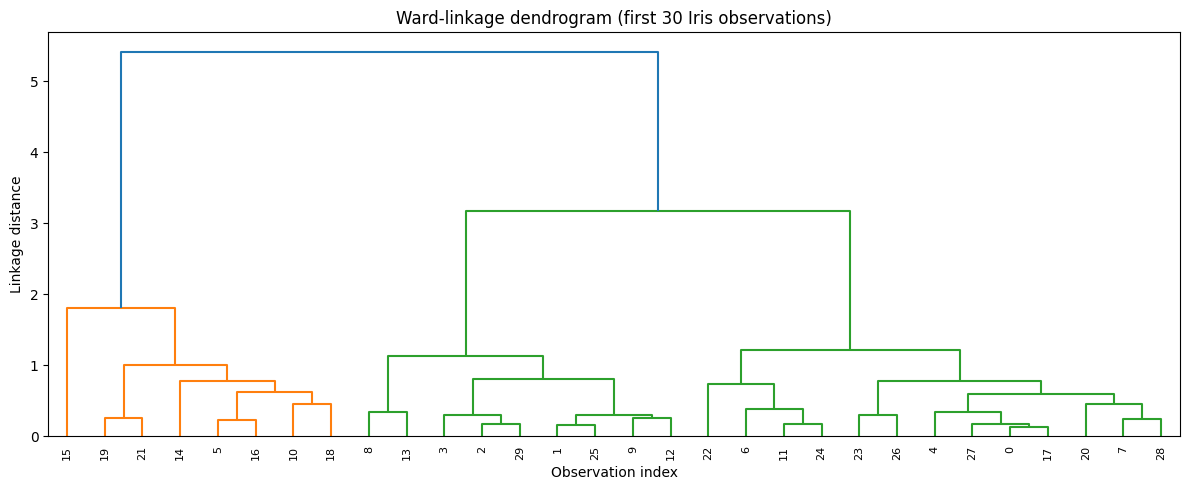

In [7]:
from sklearn.metrics import pairwise_distances, pairwise_distances_argmin
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import linkage, dendrogram

iris = load_iris(as_frame=True)
X_iris = iris.data
y_iris = iris.target

# Scale features for distance-based clustering
X_iris_scaled = StandardScaler().fit_transform(X_iris)

# Example distance and cosine similarity for the first three observations
distances = pairwise_distances(X_iris_scaled[:3], metric="euclidean")
cosine_sim = 1 - pairwise_distances(X_iris_scaled[:3], metric="cosine")
print("Euclidean distance matrix for first 3 Iris observations:")
print(np.round(distances, 3))
print("\nCosine similarity matrix for first 3 observations:")
print(np.round(cosine_sim, 3))

kmeans = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE)
kmeans_labels = kmeans.fit_predict(X_iris_scaled)

print("\nK-means silhouette score:", round(silhouette_score(X_iris_scaled, kmeans_labels), 4))
print("K-means adjusted Rand index against known Iris species (external evaluation):",
      round(adjusted_rand_score(y_iris, kmeans_labels), 4))

# Compare hierarchical linkage strategies
hier_results = []
for linkage_name in ["ward", "complete", "average", "single"]:
    if linkage_name == "ward":
        model = AgglomerativeClustering(n_clusters=3, linkage="ward")
    else:
        model = AgglomerativeClustering(n_clusters=3, linkage=linkage_name)
    labels = model.fit_predict(X_iris_scaled)
    hier_results.append({
        "Linkage": linkage_name,
        "Silhouette": silhouette_score(X_iris_scaled, labels),
        "ARI vs species": adjusted_rand_score(y_iris, labels)
    })

display(pd.DataFrame(hier_results).set_index("Linkage").round(4))

# Dendrogram on a subset for readability
Z = linkage(X_iris_scaled[:30], method="ward")
plt.figure(figsize=(12, 5))
dendrogram(Z, leaf_rotation=90, leaf_font_size=8)
plt.title("Ward-linkage dendrogram (first 30 Iris observations)")
plt.xlabel("Observation index")
plt.ylabel("Linkage distance")
plt.tight_layout()
plt.show()

**Result / inference:** Silhouette score evaluates cohesion and separation without using ground-truth labels. Adjusted Rand Index (ARI) compares cluster assignments with the known Iris species for this demonstration; it is an external metric and would not normally be available for truly unlabeled data. A dendrogram illustrates the order and distance at which clusters merge. Ward linkage minimizes the increase in within-cluster variance and is typically used with Euclidean distance.

## 2(b). Ensemble Methods — Bagging, Random Forest and Boosting

**Objective:** Implement a bagging-based Random Forest and boosting classifiers, then compare performance.

**Theory:** Bagging trains multiple models on bootstrap samples and aggregates their predictions, reducing variance. Random Forest adds random feature selection at splits. Boosting trains learners sequentially, with later learners focusing on errors or residuals made by earlier learners. This practical compares Random Forest, AdaBoost and Gradient Boosting.

In [8]:
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier

ensemble_models = {
    "Random Forest (bagging)": RandomForestClassifier(
        n_estimators=200, max_depth=None, random_state=RANDOM_STATE
    ),
    "AdaBoost": AdaBoostClassifier(n_estimators=100, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, random_state=RANDOM_STATE)
}

ensemble_results = []
for name, model in ensemble_models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)
    ensemble_results.append({
        "Model": name,
        **classification_metrics(y_test, pred),
        "Log loss": log_loss(y_test, prob)
    })

display(pd.DataFrame(ensemble_results).set_index("Model").round(4))

,Accuracy,Precision,Recall,F1,Log loss
Model,,,,,
Random Forest (bagging),0.958,0.9565,0.9778,0.9670,0.1030
AdaBoost,0.965,0.9570,0.9889,0.9727,0.4074
Gradient Boosting,0.958,0.9468,0.9889,0.9674,0.1248


**Result / inference:** Compare the metrics to identify the strongest model on this particular test split. Random Forest combines many trees trained with randomness; AdaBoost and Gradient Boosting build an additive sequence of learners. Performance depends on the dataset and hyperparameters, so there is no universally best ensemble method.

## 2(c). Gaussian Mixture Model (GMM) Clustering

**Objective:** Use a Gaussian Mixture Model to identify clusters and compare it with K-means.

**Theory:** GMM represents data as a mixture of Gaussian probability distributions. Unlike K-means' hard assignments, GMM estimates a probability of membership in each component (soft clustering). The Expectation-Maximization (EM) algorithm iteratively estimates component responsibilities and updates the mixture parameters.

In [9]:
from sklearn.mixture import GaussianMixture

gmm = GaussianMixture(n_components=3, covariance_type="full", random_state=RANDOM_STATE)
gmm_labels = gmm.fit_predict(X_iris_scaled)
gmm_probs = gmm.predict_proba(X_iris_scaled)

print("GMM converged:", gmm.converged_)
print("GMM iterations:", gmm.n_iter_)
print("GMM BIC:", round(gmm.bic(X_iris_scaled), 2))
print("GMM AIC:", round(gmm.aic(X_iris_scaled), 2))
print("GMM silhouette score:", round(silhouette_score(X_iris_scaled, gmm_labels), 4))
print("GMM ARI vs known Iris species:", round(adjusted_rand_score(y_iris, gmm_labels), 4))
print("Membership probabilities for first 5 observations:")
display(pd.DataFrame(gmm_probs[:5], columns=["Component 1", "Component 2", "Component 3"]).round(3))

GMM converged: True
GMM iterations: 11
GMM BIC: 841.19
GMM AIC: 708.72
GMM silhouette score: 0.4751
GMM ARI vs known Iris species: 0.5165
Membership probabilities for first 5 observations:


,Component 1,Component 2,Component 3
0,0.0,1.0,0.0
1,0.0,1.0,0.0
2,0.0,1.0,0.0
3,0.0,1.0,0.0
4,0.0,1.0,0.0


**Result / inference:** GMM gives soft membership probabilities, which can represent overlapping clusters. AIC and BIC balance model fit against model complexity; lower values are preferred when comparing candidate models fitted to the same data. Silhouette and ARI provide additional views of the resulting clusters.

## 2(d). Principal Component Analysis (PCA)

**Objective:** Reduce the number of features and visualize the dataset in two dimensions.

**Theory:** PCA is an unsupervised linear transformation that finds orthogonal directions of maximum variance. Components are ordered by explained variance. Standardizing features before PCA is important when variables have different scales. PCA may help visualization and reduce redundancy, but the transformed components may be less interpretable than the original features.

Explained variance ratio: [0.7296 0.2285]
Total variance explained by first two components: 0.9581


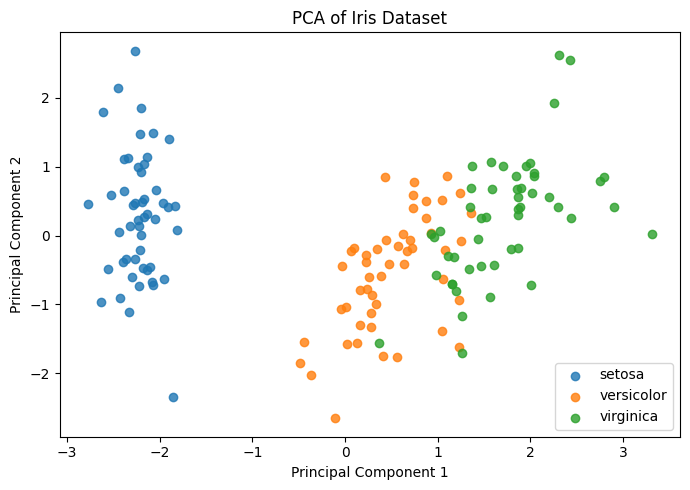

In [10]:
from sklearn.decomposition import PCA

scaler = StandardScaler()
X_iris_std = scaler.fit_transform(X_iris)

pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_iris_std)

print("Explained variance ratio:", np.round(pca.explained_variance_ratio_, 4))
print("Total variance explained by first two components:",
      round(pca.explained_variance_ratio_.sum(), 4))

pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
pca_df["Species"] = [iris.target_names[i] for i in y_iris]

plt.figure(figsize=(7, 5))
for species in iris.target_names:
    subset = pca_df[pca_df["Species"] == species]
    plt.scatter(subset["PC1"], subset["PC2"], label=species, alpha=0.8)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA of Iris Dataset")
plt.legend()
plt.tight_layout()
plt.show()

**Result / inference:** The explained variance ratio indicates how much of the standardized data variance each principal component retains. The two-dimensional scatter plot shows whether the classes separate in the reduced feature space. PCA is not itself a classifier; labels are used only to color the visualization.

# Question 3 — Performance Analysis of Models from Questions 1 and 2

## 3(a). Compare supervised classification models

This section consolidates the test-set results for Decision Tree, Logistic Regression, K-NN, Naive Bayes and ensemble classifiers using accuracy, precision, recall and F1-score. All classification models use the same train/test split from the breast-cancer dataset.

In [11]:
# Fit/evaluate a common set of classification models on the same split
comparison_models = {
    "Decision Tree (Gini)": DecisionTreeClassifier(criterion="gini", max_depth=4, random_state=RANDOM_STATE),
    "Decision Tree (Entropy)": DecisionTreeClassifier(criterion="entropy", max_depth=4, random_state=RANDOM_STATE),
    "Logistic Regression (L2)": make_pipeline(StandardScaler(), LogisticRegression(penalty="l2", C=1.0, max_iter=5000, random_state=RANDOM_STATE)),
    "Logistic Regression (L1)": make_pipeline(StandardScaler(), LogisticRegression(penalty="l1", solver="liblinear", C=1.0, max_iter=5000, random_state=RANDOM_STATE)),
    "K-NN (k=5)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "Gaussian Naive Bayes": make_pipeline(StandardScaler(), GaussianNB()),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
    "AdaBoost": AdaBoostClassifier(n_estimators=100, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, random_state=RANDOM_STATE)
}

comparison_rows = []
for name, model in comparison_models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    row = {"Model": name, **classification_metrics(y_test, pred)}
    if hasattr(model, "predict_proba"):
        row["Log loss"] = log_loss(y_test, model.predict_proba(X_test))
    elif hasattr(model, "named_steps") and hasattr(model[-1], "predict_proba"):
        row["Log loss"] = log_loss(y_test, model.predict_proba(X_test))
    comparison_rows.append(row)

classification_comparison = pd.DataFrame(comparison_rows).set_index("Model").sort_values("F1", ascending=False)
display(classification_comparison.round(4))
print("Top model by F1 on this test split:", classification_comparison.index[0])

,Accuracy,Precision,Recall,F1,Log loss
Model,,,,,
Logistic Regression (L1),0.9930,0.9890,1.0000,0.9945,0.0674
Logistic Regression (L2),0.9860,0.9889,0.9889,0.9889,0.0679
K-NN (k=5),0.9790,0.9677,1.0000,0.9836,0.3324
AdaBoost,0.9650,0.9570,0.9889,0.9727,0.4074
Gradient Boosting,0.9580,0.9468,0.9889,0.9674,0.1248
Random Forest,0.9580,0.9565,0.9778,0.9670,0.1030
Decision Tree (Entropy),0.9510,0.9560,0.9667,0.9613,1.3100
Decision Tree (Gini),0.9441,0.9556,0.9556,0.9556,1.3539
Gaussian Naive Bayes,0.9371,0.9355,0.9667,0.9508,0.4088


Top model by F1 on this test split: Logistic Regression (L1)


## 3(b). Compare regression models

The regression metrics are taken from Question 1(a). MAE and RMSE are in the target's units; MSE is in squared target units. \(R^2\) measures improvement over predicting the test-set mean and can be negative if the model performs worse than that baseline.

In [12]:
display(regression_table.sort_values("RMSE").round(3))
print("Lowest-RMSE regression model:", regression_table["RMSE"].idxmin())

,MAE,MSE,RMSE,R2
Model,,,,
Lasso (alpha=0.1),42.805,2884.624,53.709,0.456
Ridge (alpha=1.0),42.812,2892.015,53.777,0.454
Linear Regression,42.794,2900.194,53.853,0.453


Lowest-RMSE regression model: Lasso (alpha=0.1)


## 3(c). Compare clustering models

For clustering, there is no single universal performance metric. Silhouette evaluates within-cluster cohesion versus nearest-cluster separation. ARI compares cluster labels with the known Iris species labels in this example. In real unsupervised tasks, known labels may not exist, so internal measures, domain interpretation and stability analysis are important.

In [13]:
clustering_rows = [
    {
        "Method": "K-Means",
        "Silhouette": silhouette_score(X_iris_scaled, kmeans_labels),
        "ARI vs species": adjusted_rand_score(y_iris, kmeans_labels)
    },
    {
        "Method": "GMM",
        "Silhouette": silhouette_score(X_iris_scaled, gmm_labels),
        "ARI vs species": adjusted_rand_score(y_iris, gmm_labels)
    }
]
for linkage_name in ["ward", "complete", "average", "single"]:
    model = AgglomerativeClustering(n_clusters=3, linkage=linkage_name)
    labels = model.fit_predict(X_iris_scaled)
    clustering_rows.append({
        "Method": f"Hierarchical ({linkage_name})",
        "Silhouette": silhouette_score(X_iris_scaled, labels),
        "ARI vs species": adjusted_rand_score(y_iris, labels)
    })

clustering_comparison = pd.DataFrame(clustering_rows).set_index("Method").sort_values("Silhouette", ascending=False)
display(clustering_comparison.round(4))

,Silhouette,ARI vs species
Method,,
Hierarchical (single),0.5046,0.5584
Hierarchical (average),0.4803,0.5621
GMM,0.4751,0.5165
K-Means,0.4599,0.6201
Hierarchical (complete),0.4496,0.5726
Hierarchical (ward),0.4467,0.6153


## 3(d). Metric selection and final conclusion

| Task | Appropriate metrics | Interpretation |
|---|---|---|
| Regression | MAE, MSE, RMSE, \(R^2\) | Lower errors are better; higher \(R^2\) is generally better |
| Classification | Accuracy, precision, recall, F1-score, confusion matrix, log loss | Use precision/recall/F1 when class errors have different costs; lower log loss is better |
| Clustering | Silhouette score; ARI only when reference labels exist | Higher silhouette suggests better separation; higher ARI means better agreement with known labels |
| PCA | Explained variance ratio | Measures how much data variance is retained by selected components |

### Overall conclusion
This practical implemented the supervised models (Linear Regression, Ridge, Lasso, Decision Trees, Logistic Regression, K-NN and Naive Bayes), unsupervised methods (K-means, hierarchical clustering, GMM and PCA), and ensemble algorithms (Random Forest and boosting). The results demonstrate that model performance depends on the dataset, preprocessing, hyperparameters and evaluation metric. A fair comparison uses consistent train/test splits for supervised models, suitable scaling for distance- and penalty-based algorithms, and multiple metrics rather than relying on a single score.

**Submission reminder:** Before submitting, run all cells, inspect the generated outputs, and add your name, register number, date and any lab-specific formatting required by your instructor.